In [1]:
import os
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

BASE_DIR = r"E:\SmartVision-AI\data"

## EDA 1: Class Distribution

In [2]:
train_path = os.path.join(BASE_DIR, "classification", "train")

class_counts = {}

for class_name in os.listdir(train_path):
    class_folder = os.path.join(train_path, class_name)

    if os.path.isdir(class_folder):
        class_counts[class_name] = len(os.listdir(class_folder))

df = pd.DataFrame(
    class_counts.items(),
    columns=["Class", "Count"]
)

df = df.sort_values("Count", ascending=False)

print(df)

            Class  Count
0        airplane     70
1             bed     70
24          train     70
23  traffic light     70
22      stop sign     70
21   potted plant     70
20          pizza     70
19         person     70
18     motorcycle     70
17          horse     70
16       elephant     70
15            dog     70
14            cup     70
13            cow     70
12          couch     70
11          chair     70
10            cat     70
9             car     70
8            cake     70
7             bus     70
6            bowl     70
5          bottle     70
4            bird     70
3         bicycle     70
2           bench     70
25          truck     70


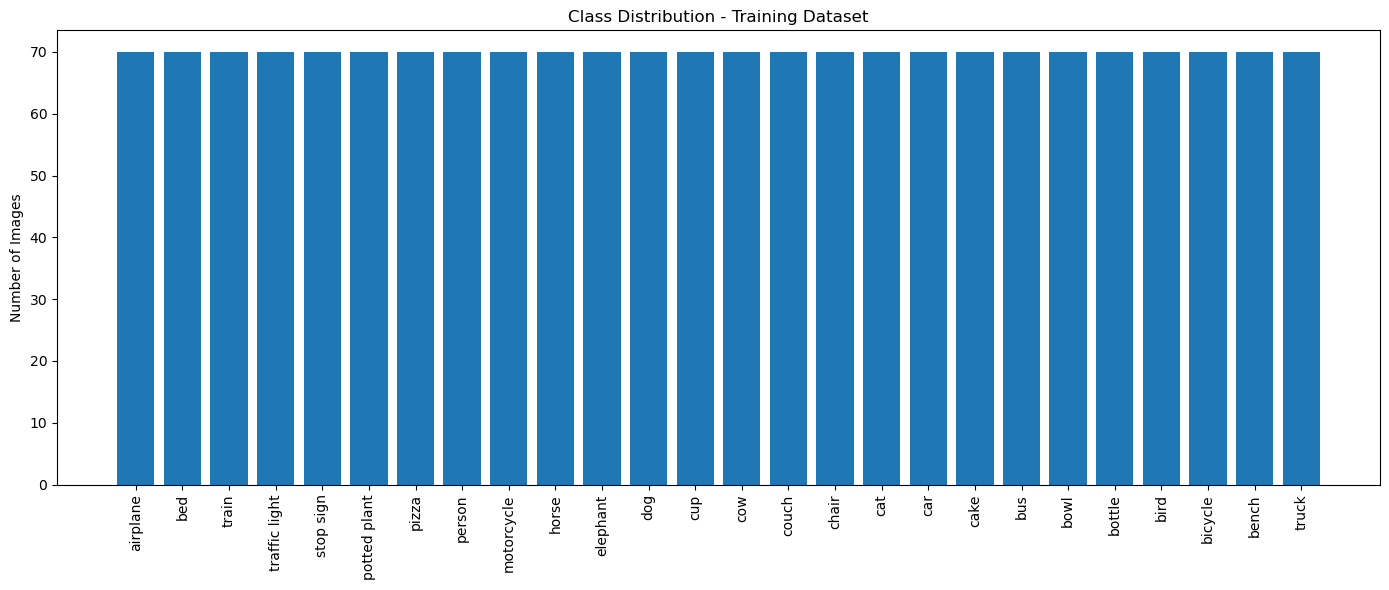

In [3]:
plt.figure(figsize=(14,6))

plt.bar(df["Class"], df["Count"])

plt.xticks(rotation=90)
plt.title("Class Distribution - Training Dataset")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

## EDA 2: Sample Images

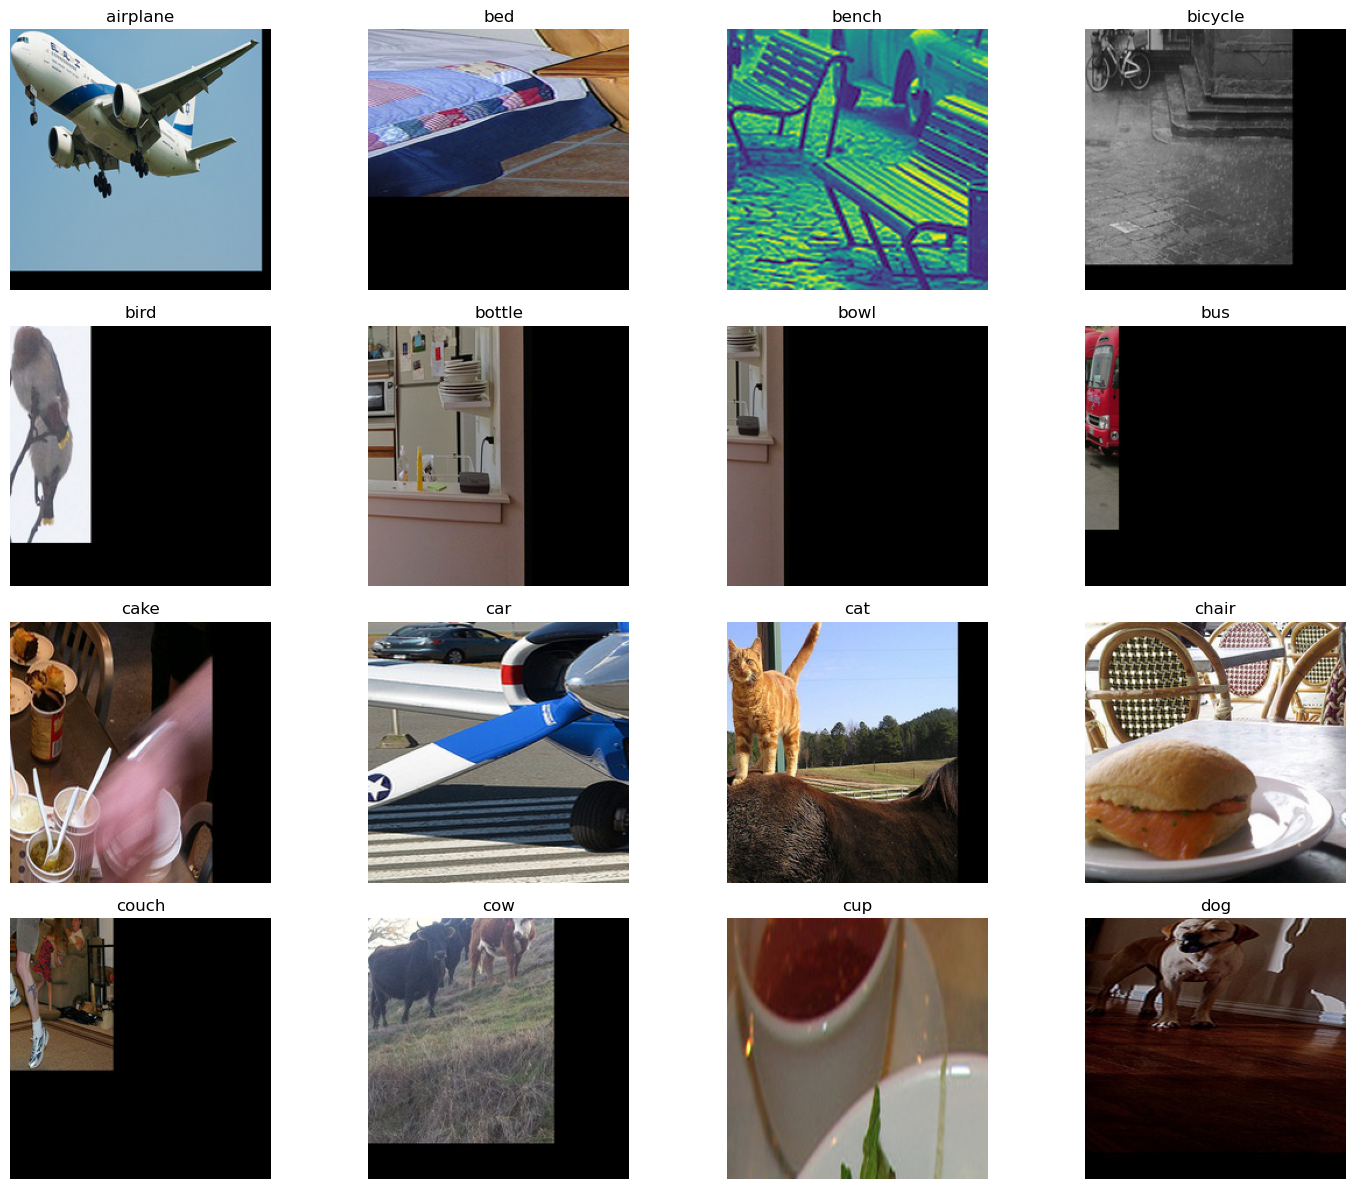

In [4]:
fig = plt.figure(figsize=(15,12))

classes = list(class_counts.keys())

for i, class_name in enumerate(classes[:16]):

    folder = os.path.join(train_path, class_name)

    img_file = random.choice(os.listdir(folder))

    img_path = os.path.join(folder, img_file)

    img = Image.open(img_path)

    plt.subplot(4,4,i+1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

## EDA: Objects per Image Distribution

In [5]:
import json
import matplotlib.pyplot as plt

metadata_path = r"E:\SmartVision-AI\data\dataset_metadata.json"

with open(metadata_path, "r") as f:
    metadata = json.load(f)

total_objects = metadata["detection"]["objects"]

total_images = (
    metadata["detection"]["train_images"]
    + metadata["detection"]["val_images"]
    + metadata["detection"]["test_images"]
)

avg_objects = total_objects / total_images

print("Total Images :", total_images)
print("Total Objects:", total_objects)
print("Average Objects per Image:", round(avg_objects, 2))

Total Images : 2600
Total Objects: 26029
Average Objects per Image: 10.01


## Dataset Summary Table

In [7]:
summary = pd.DataFrame({
    "Metric": [
        "Classes",
        "Train Images",
        "Validation Images",
        "Test Images",
        "Total Images",
        "Annotated Objects"
    ],
    "Value": [
        26,
        1820,
        390,
        390,
        2600,
        26029
    ]
})

summary

,Metric,Value
0,Classes,26
1,Train Images,1820
2,Validation Images,390
3,Test Images,390
4,Total Images,2600
5,Annotated Objects,26029


## EDA 3: Bounding Box Visualization

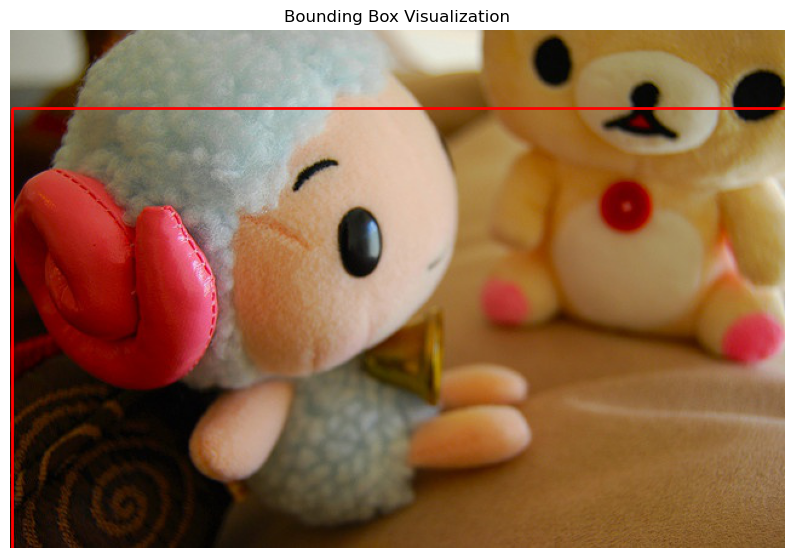

In [9]:
import os
import random
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

BASE_DIR = r"E:\SmartVision-AI\data"

image_dir = os.path.join(BASE_DIR, "detection", "images", "train")
label_dir = os.path.join(BASE_DIR, "detection", "labels", "train")

img_file = random.choice(os.listdir(image_dir))

img_path = os.path.join(image_dir, img_file)

label_path = os.path.join(
    label_dir,
    img_file.replace(".jpg", ".txt")
)

img = Image.open(img_path)

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

img_width, img_height = img.size

with open(label_path, "r") as f:

    for line in f.readlines():

        values = line.strip().split()

        class_id = int(values[0])

        x_center = float(values[1])
        y_center = float(values[2])
        w = float(values[3])
        h = float(values[4])

        # YOLO → pixel coordinates

        x = (x_center - w/2) * img_width
        y = (y_center - h/2) * img_height

        w = w * img_width
        h = h * img_height

        rect = patches.Rectangle(
            (x, y),
            w,
            h,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

plt.title("Bounding Box Visualization")
plt.axis("off")
plt.show()

## EDA 4: Image Dimension Analysis

In [10]:
from PIL import Image
import os

sample_sizes = []

train_path = os.path.join(BASE_DIR, "classification", "train")

for class_name in os.listdir(train_path):

    class_folder = os.path.join(train_path, class_name)

    if os.path.isdir(class_folder):

        img_file = os.listdir(class_folder)[0]

        img_path = os.path.join(class_folder, img_file)

        img = Image.open(img_path)

        sample_sizes.append(img.size)

print(set(sample_sizes))

{(224, 224)}


## EDA 5: Dataset Summary Report

In [11]:
summary = pd.DataFrame({
    "Metric": [
        "Classes",
        "Train Images",
        "Validation Images",
        "Test Images",
        "Total Images",
        "Annotated Objects",
        "Avg Objects/Image"
    ],
    "Value": [
        26,
        1820,
        390,
        390,
        2600,
        26029,
        round(26029/2600, 2)
    ]
})

summary

,Metric,Value
0,Classes,26.00
1,Train Images,1820.00
2,Validation Images,390.00
3,Test Images,390.00
4,Total Images,2600.00
5,Annotated Objects,26029.00
6,Avg Objects/Image,10.01


# EDA Conclusions

1. The dataset contains 26 balanced object categories.
2. Each class contains 100 images, split into:
   - Train: 70%
   - Validation: 15%
   - Test: 15%
3. The dataset contains 26,029 annotated objects.
4. Average objects per image: 10.01.
5. Classification images were successfully cropped and resized to 224×224.
6. YOLO annotations were successfully generated and verified.
7. The dataset is suitable for transfer learning and object detection tasks.